# The Provincial Bird: Winnipeg's Mosquitoes, 2015-2025

**A short report for COMP-2040 Assignment 2.** Winnipeg jokes that the mosquito is the provincial bird. Some
summers feel much worse than others: is that true, and when and where is it worst?

**The data:** City of Winnipeg Open Data, *Daily Adult Mosquito Trap Data* (exported 2026-09-13, complete seasons
2015 to 2025), cleaned in Assignment 1. One row is one count day: the average number of adult mosquitoes per trap
across the city and in each quadrant. Counts are only taken on some days, May to early October.

**Cleaning summary:** dates read day first; `no data` trap cells made missing. Details in
`../a1-mosquitoes/02-prep.ipynb`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

traps = pd.read_csv("../a1-mosquitoes/data/clean/traps-clean.csv", parse_dates=["date"])
traps.shape

(880, 46)

## Q1. Which summers were worst?

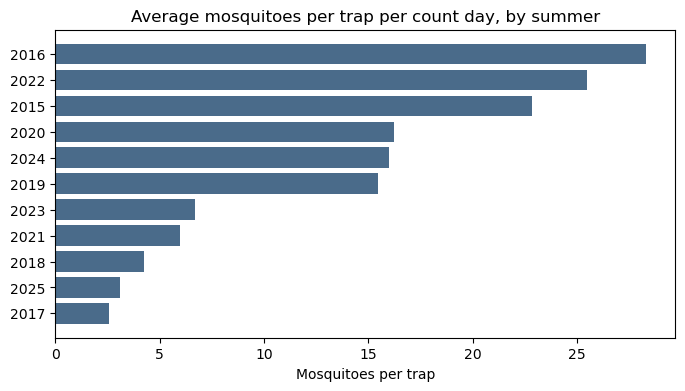

year
2017     2.6
2025     3.1
2018     4.2
2021     6.0
2023     6.7
2019    15.5
2024    16.0
2020    16.2
2015    22.9
2022    25.5
2016    28.3
Name: City Wide Daily Average, dtype: float64

In [2]:
season = traps.groupby("year")["City Wide Daily Average"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(season.index.astype(str), season.values, color="#4a6b8a")
ax.set_title("Average mosquitoes per trap per count day, by summer")
ax.set_xlabel("Mosquitoes per trap")
plt.show()
season.round(1)

## Q2. When is it worst?

In [3]:
peaks = traps.loc[traps.groupby("year")["City Wide Daily Average"].idxmax(), ["year", "date", "City Wide Daily Average"]]
peaks["month"] = peaks["date"].dt.month_name()
peaks

,year,date,City Wide Daily Average,month
19,2015,2015-06-11,151,June
237,2016,2016-06-17,187,June
140,2017,2017-07-10,19,July
162,2018,2018-07-11,20,July
416,2019,2019-07-28,108,July
426,2020,2020-06-30,101,June
372,2021,2021-07-02,42,July
494,2022,2022-08-29,235,August
698,2023,2023-06-21,53,June
524,2024,2024-07-13,138,July


## Q3. Which side of the city is buggiest?

In [4]:
sides = traps[["North West Average", "North East Average", "South East Average", "South West Average"]].mean()
sides.round(1)

North West Average    16.6
North East Average    15.1
South East Average    13.6
South West Average    15.4
dtype: float64